# EDA та моделі на multiqubit датасеті (data/raw/)

Той самий підхід, що й у [`eda_baseline_models.ipynb`](eda_baseline_models.ipynb) та
[`single_qubit_eda_models.ipynb`](single_qubit_eda_models.ipynb), застосований до
[`data/raw/multiqubit_dataset.csv`](../data/raw/README.md) (185 400 рядків, 1800 унікальних схем
на 2–8 кубітів, 8 "сімейств" — GHZ, Bell pairs, QFT-подібні тощо). Кожна схема дає кілька
спостережуваних (`Z_i` для кожного кубіта та сусідні `ZZ_i,i+1`), тому рядків більше, ніж схем.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

df = pd.read_csv("../data/raw/multiqubit_dataset.csv")
df["noise_probability"] = df["noise_params"].apply(lambda s: json.loads(s)["probability_1q"])
df["observable_type"] = df["observable"].str.startswith("ZZ").map({True: "ZZ", False: "Z"})
df.head()

,record_id,circuit_id,circuit_type,n_qubits,circuit_depth,single_qubit_gate_count,cx_count,mean_rotation_angle,observable,circuit_params,...,noise_params,backend_name,shots,seed,ideal_expval,noisy_expval,delta,timestamp,noise_probability,observable_type
0,8e16503c00c08369_Z_0_0.001_256_1181241943,8e16503c00c08369,ghz,2,5,7,1,1.1678,Z_0,"{""family"": ""ghz"", ""gates"": [{""angle"": -0.37425...",...,"{""probability_1q"": 0.001, ""probability_2q"": 0....",AerSimulator,256,1181241943,0.3564,0.3438,0.0127,2026-10-23T22:39:25.469793+00:00,0.0010,Z
1,8e16503c00c08369_Z_1_0.001_256_1181241943,8e16503c00c08369,ghz,2,5,7,1,1.1678,Z_1,"{""family"": ""ghz"", ""gates"": [{""angle"": -0.37425...",...,"{""probability_1q"": 0.001, ""probability_2q"": 0....",AerSimulator,256,1181241943,-0.1132,-0.0234,-0.0898,2026-10-23T22:39:25.469837+00:00,0.0010,Z
2,8e16503c00c08369_ZZ_0_1_0.001_256_1181241943,8e16503c00c08369,ghz,2,5,7,1,1.1678,ZZ_0_1,"{""family"": ""ghz"", ""gates"": [{""angle"": -0.37425...",...,"{""probability_1q"": 0.001, ""probability_2q"": 0....",AerSimulator,256,1181241943,-0.3176,-0.3047,-0.0129,2026-10-23T22:39:25.469869+00:00,0.0010,ZZ
3,8e16503c00c08369_Z_0_0.001_1024_1051802512,8e16503c00c08369,ghz,2,5,7,1,1.1678,Z_0,"{""family"": ""ghz"", ""gates"": [{""angle"": -0.37425...",...,"{""probability_1q"": 0.001, ""probability_2q"": 0....",AerSimulator,1024,1051802512,0.3564,0.3789,-0.0225,2026-10-23T22:39:25.476887+00:00,0.0010,Z
4,8e16503c00c08369_Z_1_0.001_1024_1051802512,8e16503c00c08369,ghz,2,5,7,1,1.1678,Z_1,"{""family"": ""ghz"", ""gates"": [{""angle"": -0.37425...",...,"{""probability_1q"": 0.001, ""probability_2q"": 0....",AerSimulator,1024,1051802512,-0.1132,-0.1484,0.0352,2026-10-23T22:39:25.476926+00:00,0.0010,Z


## 1. Перевірка якості датасету

In [2]:
print("Розмір:", df.shape)
print("Пропуски:", df.isnull().sum().sum())
print("Дублікати record_id:", df.duplicated(subset=["record_id"]).sum())
print("Унікальних схем (circuit_id):", df["circuit_id"].nunique())
print("\nСімейства схем:\n", df["circuit_type"].value_counts())
print("\nТипи спостережуваних:\n", df["observable_type"].value_counts())
print("\nВаріанти shots:", sorted(df["shots"].unique()))
print("Унікальних рівнів шуму:", df["noise_probability"].nunique())

Розмір: (185400, 21)
Пропуски: 0
Дублікати record_id: 0
Унікальних схем (circuit_id): 1800

Сімейства схем:
 circuit_type
ghz                   23175
bell_pairs            23175
rotation_cx_ladder    23175
rotation_cx_ring      23175
random_rotation_cx    23175
qft_like              23175
bv_like               23175
cx_dense_random       23175
Name: count, dtype: int64

Типи спостережуваних:
 observable_type
Z     106200
ZZ     79200
Name: count, dtype: int64

Варіанти shots: [np.int64(256), np.int64(1024), np.int64(4096)]
Унікальних рівнів шуму: 5


**Висновок:** без пропусків і дублікатів, 1800 унікальних схем рівномірно розподілені між
8 сімействами. Кількість рядків на спостережувану зменшується зі зростанням кількості кубітів —
очікувано, бо кількість згенерованих схем на більші розміри менша (`CIRCUITS_PER_QUBIT_COUNT` у
коді генерації).

## 2. Розподіл `delta` та залежність від шуму, shots, кубітів і глибини

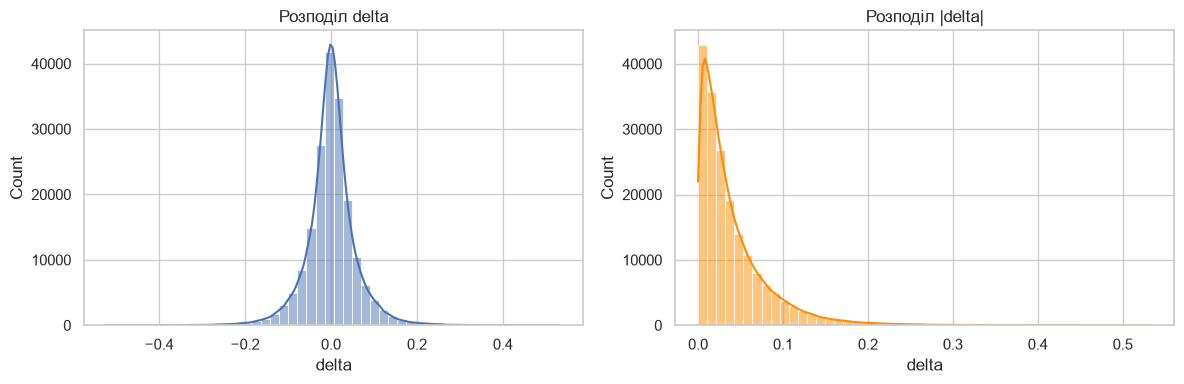

count   185400.0000
mean         0.0001
std          0.0580
min         -0.5212
25%         -0.0264
50%          0.0001
75%          0.0266
max          0.5337
Name: delta, dtype: float64

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["delta"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Розподіл delta")
sns.histplot(df["delta"].abs(), bins=50, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Розподіл |delta|")
plt.tight_layout()
plt.show()
df["delta"].describe()

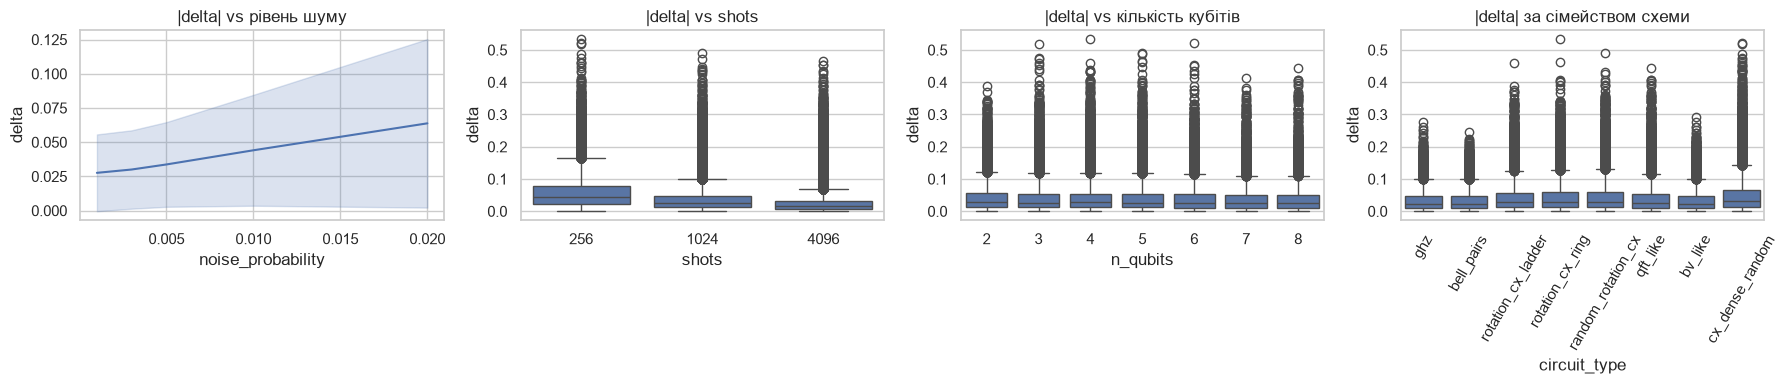

Кореляція з |delta|:
noise_probability          0.3136
circuit_depth              0.1407
cx_count                   0.0998
single_qubit_gate_count    0.0993
n_qubits                  -0.0292
shots                     -0.2386
Name: abs_delta, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

sns.lineplot(data=df, x="noise_probability", y=df["delta"].abs(), ax=axes[0], errorbar="sd")
axes[0].set_title("|delta| vs рівень шуму")

sns.boxplot(data=df, x="shots", y=df["delta"].abs(), ax=axes[1])
axes[1].set_title("|delta| vs shots")

sns.boxplot(data=df, x="n_qubits", y=df["delta"].abs(), ax=axes[2])
axes[2].set_title("|delta| vs кількість кубітів")

sns.boxplot(data=df, x="circuit_type", y=df["delta"].abs(), ax=axes[3])
axes[3].set_title("|delta| за сімейством схеми")
axes[3].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

corr = df[["n_qubits", "circuit_depth", "single_qubit_gate_count", "cx_count", "noise_probability", "shots"]].assign(
    abs_delta=df["delta"].abs()
).corr()["abs_delta"].drop("abs_delta")
print("Кореляція з |delta|:")
print(corr.sort_values(ascending=False))

**Висновок з EDA:** найсильніший зв'язок — з рівнем шуму (0.31) і кількістю `shots` (−0.24,
більше вимірювань → менше похибки, як і очікувалось). Глибина/кількість CX впливають значно слабше
(~0.10–0.14). Кількість кубітів практично не корелює напряму — логічно, бо спостережувана `Z_i`/`ZZ`
локальна, її точність визначається радше локальним шумом і shots, ніж загальним розміром схеми.

## 3. Ознаки, ціль, розділення train/validation/test

Поділ за `circuit_id` (80/10/10), щоб жодна схема (і всі її спостережувані/рівні шуму/shots) не
потрапила одночасно в кілька частин.

In [5]:
num_features = ["n_qubits", "circuit_depth", "single_qubit_gate_count", "cx_count",
                "mean_rotation_angle", "noise_probability", "shots"]
cat_features = ["circuit_type", "observable_type"]
features = num_features + cat_features
target = "delta"

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, temp_idx = next(gss.split(df, groups=df["circuit_id"]))
train, temp = df.iloc[train_idx], df.iloc[temp_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss2.split(temp, groups=temp["circuit_id"]))
val, test = temp.iloc[val_idx], temp.iloc[test_idx]

print(f"train: {len(train)}, validation: {len(val)}, test: {len(test)}")
print("Перетин circuit_id між train і test:", len(set(train.circuit_id) & set(test.circuit_id)))

train: 147630, validation: 19140, test: 18630
Перетин circuit_id між train і test: 0


## 4. Моделі

In [6]:
def make_pipeline(model):
    pre = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)],
        remainder="passthrough",
    )
    return Pipeline([("pre", pre), ("scale", StandardScaler(with_mean=False)), ("model", model)])


models = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1.0)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, random_state=42, n_jobs=-1),
    "Small MLP": MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=300, random_state=42, early_stopping=True),
}

def evaluate(pipe, X, y):
    pred = pipe.predict(X)
    return {
        "MAE": mean_absolute_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
        "R2": r2_score(y, pred),
    }

fitted = {}
rows = []
for name, model in models.items():
    pipe = make_pipeline(model)
    pipe.fit(train[features], train[target])
    fitted[name] = pipe
    for split_name, split_df in [("validation", val), ("test", test)]:
        rows.append({"model": name, "split": split_name, **evaluate(pipe, split_df[features], split_df[target])})

results = pd.DataFrame(rows)
results

,model,split,MAE,RMSE,R2
0,Dummy (mean),validation,0.0420,0.0608,-0.0000
1,Dummy (mean),test,0.0403,0.0594,-0.0001
2,Linear Regression,validation,0.0419,0.0608,0.0005
3,Linear Regression,test,0.0403,0.0594,0.0006
4,Ridge (alpha=1.0),validation,0.0419,0.0608,0.0005
5,Ridge (alpha=1.0),test,0.0403,0.0594,0.0006
6,Random Forest,validation,0.0421,0.0610,-0.0052
7,Random Forest,test,0.0406,0.0601,-0.0217
8,XGBoost,validation,0.0422,0.0610,-0.0082
9,XGBoost,test,0.0411,0.0603,-0.0302


In [7]:
raw_mae_test = test["delta"].abs().mean()
print(f"Без корекції (raw) на test: MAE={raw_mae_test:.4f}")
comparison_test = results[results["split"] == "test"].drop(columns="split").set_index("model").sort_values("MAE")
comparison_test

Без корекції (raw) на test: MAE=0.0403


,MAE,RMSE,R2
model,,,
Ridge (alpha=1.0),0.0403,0.0594,0.0006
Linear Regression,0.0403,0.0594,0.0006
Dummy (mean),0.0403,0.0594,-0.0001
Random Forest,0.0406,0.0601,-0.0217
XGBoost,0.0411,0.0603,-0.0302
Small MLP,0.0411,0.0601,-0.0219


## Висновок

Та сама картина, що й на `single_qubit_dataset.csv`: попри реальні, логічні залежності `|delta|`
від рівня шуму та `shots` на **агрегованому** рівні (розділ 2), жодна модель не покращує
прогноз помітно над простим middle/без корекції — MAE моделей практично дорівнює `raw MAE`, R²
близький до нуля або від'ємний.

**Це узгоджений, а не випадковий результат для обох датасетів Василя.** Ключова відмінність від
основного датасету (де Random Forest дав R²=0.70): там кожна (схема, профіль шуму) комбінація
покрита 1024 вимірюваннями з **фіксованим** числом shots і відносно сильними ручними рівнями шуму
(0.002–0.048), тож систематична похибка явно переважала статистичний шум одного запуску. У датасетах
Василя рівні шуму нижчі (0.001–0.05 на single-qubit, 0.001–0.02 на multiqubit) і shots варіюються
аж до 256 — за таких умов статистичний шум вимірювання (shot noise) стає порівнянним або більшим за
систематичну похибку, яку модель могла б вивчити, тому передбачення `delta` для окремого запуску
впирається в межу, яку неможливо подолати цими ознаками.

**Практичний висновок для проєкту:** ML-корекція такого типу доцільна там, де систематична похибка
домінує над shot noise (глибші/ширші схеми з помітним рівнем шуму й достатньою кількістю shots, як
в основному датасеті) — а не для малошумних/малошотових режимів. Якщо продовжувати роботу з
датасетами Василя, варто або збільшити кількість shots (зменшити statistical noise), або усереднити
кілька повторів одного (схема, шум) поєднання перед обчисленням `delta` — це прибрало б частину
нерозрізнюваного статистичного шуму й дало моделі шанс вивчити власне систематичну складову.